# ML01: Labels from IMD gauge rainfall (Tasks 2 and 3)
**Goal:** build the target the model will learn to predict: **is tomorrow an extreme rain day over the Chenab-Ravi catchments?**

**Steps**
1. Download IMD 0.25° daily rain 1979-2025 (shared with your flood paper, so files already on Drive are skipped).
2. Average the rain over each basin (cos-latitude weighted), June-September only.
3. Define an **extreme day** = basin rain at or above the **95th percentile** of all JJAS days 1979-2024 (2025 is never used to set the threshold).

**Date convention (same as the flood paper):** IMD rain-day = 24 h ending 08:30 IST (03 UTC), labelled here by its **START** date. IMD official date = start + 1 day.

**Time:** first run 20-40 min (download), later runs about 1 min. If Colab disconnects, run all cells again; finished years are skipped.

In [1]:
!pip install -q imdlib geopandas

In [2]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

import geopandas as gpd, shapely
IMD_DIR  = f'{EPE}/data/imd'                     # the same folder your Step 5 uses
IMD_PROC = f'{DATA}/imd_proc'
os.makedirs(IMD_DIR, exist_ok=True); os.makedirs(IMD_PROC, exist_ok=True)

u = gpd.read_file(f'{EPE}/Shapefiles/EasternRiversBasins_L12.shp').to_crs('EPSG:4326')
units = dict(zip(u['river'], u.geometry))
outer = gpd.read_file(f'{EPE}/Shapefiles/EasternRiversBasins_L12_Dissolved.shp').to_crs('EPSG:4326').geometry.union_all()
U = shapely.unary_union
domains = {'all': outer,
           'ChenabRavi': U([units['Chenab'], units['Ravi']]),
           'BeasSutlej': U([units['Beas'], units['Sutlej']])}
print('domains:', list(domains))

Mounted at /content/drive
domains: ['all', 'ChenabRavi', 'BeasSutlej']


## 1. Download IMD daily rain 1979-2025 (slow only the first time)

In [3]:
import imdlib as imd
NLAT, NLON = 129, 135
LAT = 6.5 + 0.25 * np.arange(NLAT); LON = 66.5 + 0.25 * np.arange(NLON)
def ndays(yr): return 366 if pd.Timestamp(f'{yr}-12-31').dayofyear == 366 else 365
def grd_ok(yr):
    f = f'{IMD_DIR}/rain/{yr}.grd'
    return os.path.exists(f) and os.path.getsize(f) == ndays(yr) * NLAT * NLON * 4

for yr in YEARS:
    if grd_ok(yr): continue
    print('downloading IMD', yr, flush=True)
    try: imd.get_data('rain', yr, yr, fn_format='yearwise', file_dir=IMD_DIR)
    except Exception as ex: print('  FAILED', yr, repr(ex)[:150], '-> run this cell again later')
missing = [y for y in YEARS if not grd_ok(y)]
print('IMD years on Drive:', len(YEARS) - len(missing), 'of', len(YEARS), '| missing:', missing)

IMD years on Drive: 47 of 47 | missing: []


## 2. Basin-mean daily rain, June-September (one small CSV per year, crash-safe)

In [4]:
def read_imd_year(yr):
    raw = np.fromfile(f'{IMD_DIR}/rain/{yr}.grd', dtype='<f4')
    nd = ndays(yr)
    arr = raw[:nd * NLAT * NLON].reshape(nd, NLAT, NLON)
    arr = np.where(arr <= -998, np.nan, arr)
    da = xr.DataArray(arr, dims=('time', 'latitude', 'longitude'),
                      coords={'time': pd.date_range(f'{yr}-01-01', periods=nd), 'latitude': LAT, 'longitude': LON})
    # orientation check: Delhi must be land, the Arabian Sea must be missing
    assert np.isfinite(da.sel(latitude=28.5, longitude=77.25, method='nearest')).mean() > 0.9
    assert np.isfinite(da.sel(latitude=15.0, longitude=68.0, method='nearest')).mean() < 0.1
    # IMD labels a rain-day by its END date (08:30 IST); relabel by START date
    return da.assign_coords(time=da.get_index('time') - pd.Timedelta(days=1))

LON2, LAT2 = np.meshgrid(LON, LAT)
masks = {k: xr.DataArray(shapely.contains_xy(g, LON2, LAT2), coords={'latitude': LAT, 'longitude': LON},
                         dims=('latitude', 'longitude')) for k, g in domains.items()}
print({k: int(m.sum()) for k, m in masks.items()}, '(IMD cells per domain)')
coslat = xr.DataArray(np.cos(np.deg2rad(LAT)), coords={'latitude': LAT}, dims='latitude')

def basin_mean(da, m):
    w = coslat.broadcast_like(m).where(m).fillna(0)
    return da.where(m).weighted(w).mean(['latitude', 'longitude'])

for yr in YEARS:
    out = f'{IMD_PROC}/imd_basin_{yr}.csv'
    if os.path.exists(out) or not grd_ok(yr): continue
    da = read_imd_year(yr).sel(time=slice(f'{yr}-06-01', f'{yr}-09-30'))
    df = pd.DataFrame({k: basin_mean(da, m).to_series() for k, m in masks.items()})
    df.index.name = 'date'; df.round(3).to_csv(out)
    print(yr, len(df), 'days', flush=True)

imd_daily = pd.concat([pd.read_csv(f, index_col=0, parse_dates=True)
                       for f in sorted(glob.glob(f'{IMD_PROC}/imd_basin_*.csv'))]).sort_index()
imd_daily.to_csv(f'{DATA}/imd_basin_daily_JJAS.csv')
print(imd_daily.index.year.nunique(), 'years,', len(imd_daily), 'days')

{'all': 138, 'ChenabRavi': 63, 'BeasSutlej': 68} (IMD cells per domain)
1979 122 days
1980 122 days
1981 122 days
1982 122 days
1983 122 days
1984 122 days
1985 122 days
1986 122 days
1987 122 days
1988 122 days
1989 122 days
1990 122 days
1991 122 days
1992 122 days
1993 122 days
1994 122 days
1995 122 days
1996 122 days
1997 122 days
1998 122 days
1999 122 days
2000 122 days
2001 122 days
2002 122 days
2003 122 days
2004 122 days
2005 122 days
2006 122 days
2007 122 days
2008 122 days
2009 122 days
2010 122 days
2011 122 days
2012 122 days
2013 122 days
2014 122 days
2015 122 days
2016 122 days
2017 122 days
2018 122 days
2019 122 days
2020 122 days
2021 122 days
2022 122 days
2023 122 days
2024 122 days
2025 122 days
47 years, 5734 days


## 3. Check against your flood paper (must print about 183 and 173 mm, and 47 years)

In [5]:
d = imd_daily['all']
print('E1 whole-basin total:', round(d.loc[slice(*EPISODES['E1'])].sum()), 'mm (paper: 183)')
print('E2 whole-basin total:', round(d.loc[slice(*EPISODES['E2'])].sum()), 'mm (paper: 173)')
print(imd_daily.index.year.nunique(), 'years')

E1 whole-basin total: 183 mm (paper: 183)
E2 whole-basin total: 173 mm (paper: 173)
47 years


## 4. Define extreme days (the labels)
The threshold uses only 1979-2024, so 2025 stays a fair test.

In [6]:
rain = imd_daily[TARGET]
thr = np.nanpercentile(rain[rain.index.year.isin(TRAIN_YEARS)], PCT)
lab = pd.DataFrame({'rain': rain, 'extreme': (rain >= thr).astype(int)})
lab.to_csv(f'{DATA}/labels_{TARGET}_p{PCT}.csv')

per_year = lab.groupby(lab.index.year)['extreme'].sum()
print(f'{TARGET}: {PCT}th percentile threshold = {thr:.1f} mm/day')
print(f'extreme days 1979-2024: {per_year.loc[TRAIN_YEARS].sum()} '
      f'(base rate {lab.loc[lab.index.year <= 2024, "extreme"].mean():.3f}, about {per_year.loc[TRAIN_YEARS].mean():.1f} per season)')
x25 = lab[(lab.index.year == 2025) & (lab.extreme == 1)]
print('2025 extreme days (start-date labels):', ', '.join(f'{d:%d %b} ({r:.0f} mm)' for d, r in x25['rain'].items()))

ChenabRavi: 95th percentile threshold = 18.9 mm/day
extreme days 1979-2024: 281 (base rate 0.050, about 6.1 per season)
2025 extreme days (start-date labels): 20 Jul (31 mm), 21 Jul (20 mm), 29 Jul (28 mm), 31 Jul (20 mm), 11 Aug (37 mm), 14 Aug (27 mm), 23 Aug (40 mm), 24 Aug (32 mm), 25 Aug (63 mm), 26 Aug (93 mm), 29 Aug (27 mm), 01 Sep (28 mm), 02 Sep (75 mm), 03 Sep (25 mm)


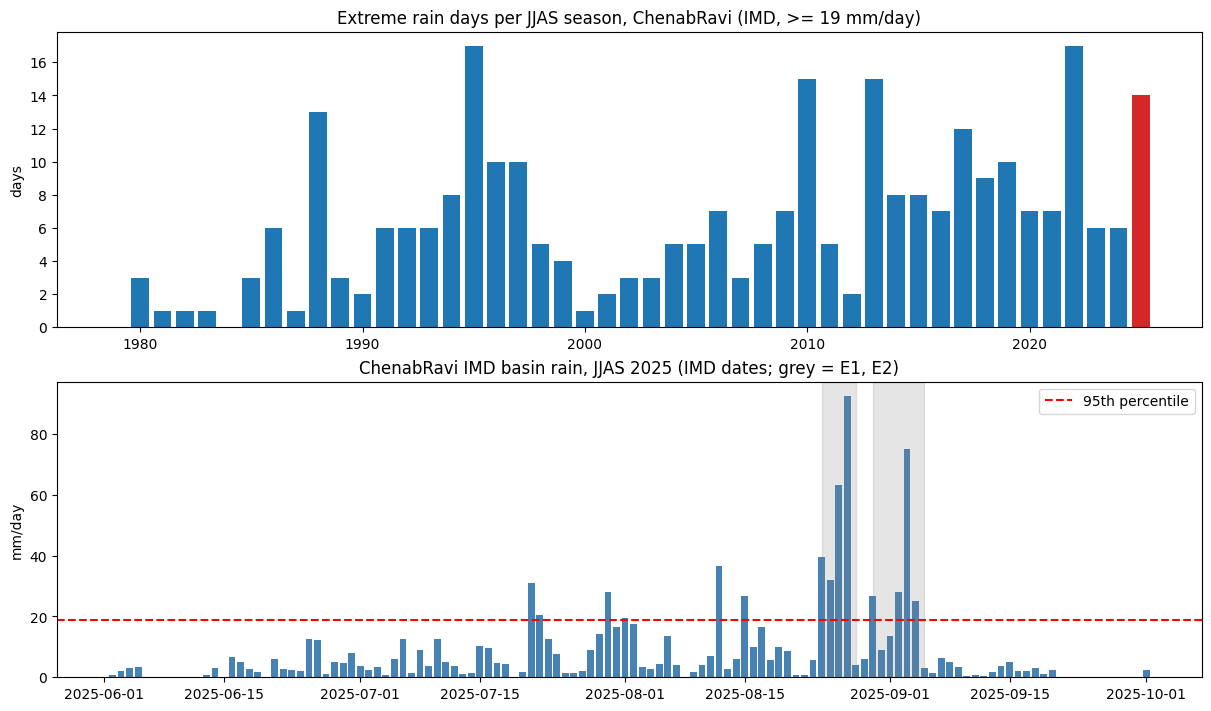

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
ax[0].bar(per_year.index, per_year.values, color=['tab:red' if y == 2025 else 'tab:blue' for y in per_year.index])
ax[0].set_title(f'Extreme rain days per JJAS season, {TARGET} (IMD, >= {thr:.0f} mm/day)'); ax[0].set_ylabel('days')
r25 = lab.loc['2025-06-01':'2025-09-30', 'rain']
ax[1].bar(r25.index + pd.Timedelta(days=1), r25.values, color='steelblue')      # plotted on the IMD date
ax[1].axhline(thr, color='red', ls='--', label=f'{PCT}th percentile')
for k, (a, b) in EPISODES.items():
    ax[1].axvspan(pd.Timestamp(a) + pd.Timedelta(days=1), pd.Timestamp(b) + pd.Timedelta(days=2), color='grey', alpha=.2)
ax[1].set_title(f'{TARGET} IMD basin rain, JJAS 2025 (IMD dates; grey = E1, E2)'); ax[1].set_ylabel('mm/day'); ax[1].legend()
plt.savefig(f'{RES}/ml01_labels.png', dpi=150); plt.show()

## Think about it (answer in 2-3 lines and send to Claude)
1. How many extreme days per season does the 95th percentile give? Why not use the 99th percentile for a first model?
2. Do extreme days come more often in some years? What could cause that (think ENSO, active and break monsoon)?
3. Why must the threshold be computed **without** 2025?